# 쇼핑몰에서 누가 자주 오고 많이 사는지 분석해서 단골 찾기

H&M 패션 쇼핑몰의 거래·고객·상품 데이터(상품 이미지 포함)를 분석한다. 이 노트북은 `src/pipeline.py`의 `DataAnalyzer` 클래스를 불러와 다음 순서로 진행한다.

1. 데이터 로드와 기본 탐색
2. 피처 엔지니어링(상품명, 이미지)
3. 결측치 대치와 이상치 처리
4. 통계 분석과 시각화
5. RFM 고객 세분화

In [1]:
import sys
from pathlib import Path

# 이 노트북은 notebooks/ 폴더에서 실행되므로, 부모 폴더(프로젝트 루트)를
# import 경로에 추가해 src/pipeline.py를 불러올 수 있게 한다.
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.pipeline import DataAnalyzer

import matplotlib.pyplot as plt

# 차트의 한글이 깨지지 않도록 설치된 폰트 중 첫 번째를 쓴다.
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["AppleGothic", "Malgun Gothic", "NanumGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

## 1. 데이터 로드

`DataAnalyzer().load_data()`는 거래·고객·상품 CSV 세 개를 읽는다. 이때 두 가지를 지킨다.

- `customer_id`, `article_id` 같은 ID 컬럼은 **문자열**로 읽는다. 숫자로 읽으면 `0706016001` 같은 상품 ID의 앞자리 0이 사라져 이미지 경로와 다른 테이블과의 연결이 끊긴다.
- `order_date`, `first_sold_date`는 **날짜형**으로 읽는다.

In [2]:
analyzer = DataAnalyzer().load_data()

tables = {
    "transactions (거래)": analyzer.transactions,
    "customers (고객)": analyzer.customers,
    "articles (상품)": analyzer.articles,
}
for name, df in tables.items():
    print(f"{name:<22} {df.shape[0]:>6,}행 x {df.shape[1]}열")

transactions (거래)      27,728행 x 5열
customers (고객)          2,000행 x 7열
articles (상품)           1,500행 x 29열


In [3]:
print("article_id 예시:", analyzer.articles["article_id"].iloc[0])
print("article_id 자료형:", analyzer.articles["article_id"].dtype)

order_dates = analyzer.transactions["order_date"]
print("order_date 자료형:", order_dates.dtype)
print("order_date 범위:", order_dates.min().date(), "~", order_dates.max().date())

article_id 예시: 0706016001
article_id 자료형: str
order_date 자료형: datetime64[us]
order_date 범위: 2019-09-23 ~ 2020-09-22


## 2. 기본 탐색

세 테이블에 `head()`(앞 5행), `info()`(컬럼별 자료형과 비어 있지 않은 값의 개수), `describe()`(수치 컬럼의 개수·평균·표준편차·사분위수)를 실행해 구조를 파악한다. 모든 해석은 **수치 근거 1개 이상 + 시사점 1문장 이상**으로 쓴다.

### 2-1. 거래 데이터 (`transactions`)

거래 1행은 고객이 상품 1개를 산 기록이다. RFM 분석(Recency·Frequency·Monetary)의 재료가 된다.

In [4]:
analyzer.transactions.head()

,order_date,customer_id,article_id,amount,sales_channel_id
0,2019-09-23,056d5837612bf72b000a552a5c60c80a15367706f9dc60...,0739680002,0.005797,1
1,2019-09-23,056d5837612bf72b000a552a5c60c80a15367706f9dc60...,0739680002,0.005797,1
2,2019-09-23,056d5837612bf72b000a552a5c60c80a15367706f9dc60...,0796232001,0.033881,2
3,2019-09-23,056d5837612bf72b000a552a5c60c80a15367706f9dc60...,0796232001,0.033881,2
4,2019-09-23,056d5837612bf72b000a552a5c60c80a15367706f9dc60...,0179123001,0.014508,1


In [5]:
analyzer.transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 27728 entries, 0 to 27727
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_date        27728 non-null  datetime64[us]
 1   customer_id       27728 non-null  str           
 2   article_id        27728 non-null  str           
 3   amount            27728 non-null  float64       
 4   sales_channel_id  27728 non-null  int64         
dtypes: datetime64[us](1), float64(1), int64(1), str(2)
memory usage: 1.1 MB


In [6]:
analyzer.transactions.describe().round(4)

,order_date,amount,sales_channel_id
count,27728,27728.0000,27728.0000
mean,2020-03-27 22:12:17.449509,0.0281,1.7064
min,2019-09-23 00:00:00,0.0007,1.0000
25%,2019-12-23 00:00:00,0.0169,1.0000
50%,2020-04-08 00:00:00,0.0254,2.0000
75%,2020-06-25 00:00:00,0.0339,2.0000
max,2020-09-22 00:00:00,0.3373,2.0000
std,NaN,0.0187,0.4554


In [7]:
tx = analyzer.transactions
n_customers = tx["customer_id"].nunique()
print(f"거래 {len(tx):,}건, 고유 고객 {n_customers:,}명, 고객당 평균 {len(tx) / n_customers:.2f}건")
print("판매 채널별 건수:", tx["sales_channel_id"].value_counts().to_dict())
print(f"amount 최댓값 / 중앙값 = {tx['amount'].max() / tx['amount'].median():.1f}배")

거래 27,728건, 고유 고객 2,000명, 고객당 평균 13.86건
판매 채널별 건수: {2: 19587, 1: 8141}
amount 최댓값 / 중앙값 = 13.3배


**해석 — 거래 데이터**

- **수치 근거:** 거래는 27,728건, 고객은 2,000명으로 고객당 평균 약 13.9건이다. 결제 금액 `amount`는 평균 0.0281, 중앙값 0.0254, 최댓값 0.3373로, 평균이 중앙값보다 크고 최댓값은 중앙값의 약 13배다.
- **시사점:** 소수의 고가 거래가 평균을 끌어올리는 오른쪽으로 긴 분포로 보인다. `amount`는 원화나 달러가 아닌 상대값이므로, 금액은 "몇 원"이 아니라 "다른 고객·거래와의 상대 크기"로 해석해야 하고, 고객별 금액 합계(RFM의 Monetary)를 볼 때도 큰 거래의 영향을 감안해야 한다.

### 2-2. 고객 데이터 (`customers`)

고객 1행은 고객 1명이다. `FN`과 `Active`는 값이 1이거나 비어 있는 표시 컬럼이다.

In [8]:
analyzer.customers.head()

,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00511323d252c93be07a61a61891bc8ff0ffdf547573fc...,1.0,1.0,ACTIVE,Regularly,58.0,f3618817f36086a3a71cacf19369ba411083206758cb7b...
1,006614ef971c0097e28a98c8c1d7127088c7dae2721eac...,NaN,NaN,PRE-CREATE,NONE,50.0,b935d7a9b07fc2e9779f88dbda6d14570116f00b56c912...
2,006e3b308be2c29584e79e4c87df8c7fd45ebe5ce2bbb8...,1.0,1.0,ACTIVE,Regularly,21.0,2c29ae653a9282cce4151bd87643c907644e09541abc28...
3,006e4ef0f8243b60eb0e94c1d851254f8cf0ce45fbb8b8...,NaN,NaN,ACTIVE,NONE,58.0,ad18f8a527437d83ef46d2d2e267bb0b674187067fa5f2...
4,00998ab46e0ad7e77e4ea9dc0e2109c15e055d0c20acfc...,1.0,1.0,ACTIVE,Regularly,51.0,d2bb93612bd38b18f1939df4949f871f3085d99d0ffdf6...


In [9]:
analyzer.customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             2000 non-null   str    
 1   FN                      715 non-null    float64
 2   Active                  704 non-null    float64
 3   club_member_status      1995 non-null   str    
 4   fashion_news_frequency  1971 non-null   str    
 5   age                     1981 non-null   float64
 6   postal_code             2000 non-null   str    
dtypes: float64(3), str(4)
memory usage: 109.5 KB


In [10]:
analyzer.customers.describe().round(2)

,FN,Active,age
count,715.0,704.0,1981.00
mean,1.0,1.0,35.65
std,0.0,0.0,14.06
min,1.0,1.0,17.00
25%,1.0,1.0,24.00
50%,1.0,1.0,31.00
75%,1.0,1.0,48.00
max,1.0,1.0,79.00


In [11]:
customers = analyzer.customers
missing = customers.isna().sum().to_frame("결측 개수")
missing["결측률(%)"] = (missing["결측 개수"] / len(customers) * 100).round(1)
print("FN 값:", sorted(customers["FN"].dropna().unique()), "/ Active 값:", sorted(customers["Active"].dropna().unique()))
missing

FN 값: [np.float64(1.0)] / Active 값: [np.float64(1.0)]


,결측 개수,결측률(%)
customer_id,0,0.0
FN,1285,64.2
Active,1296,64.8
club_member_status,5,0.2
fashion_news_frequency,29,1.5
age,19,1.0
postal_code,0,0.0


**해석 — 고객 데이터**

- **수치 근거:** 고객 2,000명 중 나이(`age`)가 있는 사람은 1,981명이고 19명은 비어 있다. 나이의 중앙값은 31세, 평균은 35.65세이고, 25%가 24세 이하, 75%가 48세 이하다.
- **시사점:** 평균이 중앙값보다 높아 젊은 층에 몰려 있고 나이가 많은 쪽으로 꼬리가 긴 분포다. 나이 결측은 19명(0.95%)으로 비중이 작지만, 결측 처리(5단계)에서 그룹별 통계로 대치할 대상이다.
- **수치 근거:** `FN`은 1,285명(64.2%), `Active`는 1,296명(64.8%)이 비어 있고, 값이 있는 경우는 모두 1 하나뿐이다.
- **시사점:** 원본이 빈 값의 의미("아니오"인지 "모름"인지)를 설명하지 않으므로 빈 값을 0으로 단정하지 않고, 의미를 확인하기 전에는 분석 변수로 쓰지 않는다.

### 2-3. 상품 데이터 (`articles`)

상품 1행은 상품 1개다. 상품명(텍스트), 가격·판매량(수치), 종류·색상(범주), 첫 판매일(날짜), 이미지 파일 경로를 한 표에 갖고 있다.

In [12]:
analyzer.articles.head()

,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,...,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc,sales_count,avg_price,first_sold_date,image_path
0,0706016001,0706016,Jade HW Skinny Denim TRS,272,Trousers,Garment Lower body,1010016,Solid,9,Black,...,Divided,53,Divided Collection,1009,Trousers,High-waisted jeans in washed superstretch deni...,30209,0.032122,2018-11-27,images/070/0706016001.jpg
1,0720125001,0720125,SUPREME RW tights,273,Leggings/Tights,Garment Lower body,1010016,Solid,9,Black,...,Sport,5,Ladies H&M Sport,1005,Jersey Fancy,Sports tights in fast-drying functional fabric...,17182,0.032350,2019-05-28,images/072/0720125001.jpg
2,0706016002,0706016,Jade HW Skinny Denim TRS,272,Trousers,Garment Lower body,1010016,Solid,71,Light Blue,...,Divided,53,Divided Collection,1009,Trousers,High-waisted jeans in washed superstretch deni...,16872,0.031901,2018-11-02,images/070/0706016002.jpg
3,0372860001,0372860,7p Basic Shaftless,302,Socks,Socks & Tights,1010016,Solid,9,Black,...,Ladieswear,62,"Womens Nightwear, Socks & Tigh",1021,Socks and Tights,Fine-knit trainer socks in a soft cotton blend.,15429,0.012942,2018-09-20,images/037/0372860001.jpg
4,0759871002,0759871,Tilda tank,253,Vest top,Garment Upper body,1010016,Solid,9,Black,...,Divided,80,Divided Complements Other,1002,Jersey Basic,"Cropped, fitted top in cotton jersey with narr...",15295,0.006127,2019-03-05,images/075/0759871002.jpg


In [13]:
analyzer.articles.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 29 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   article_id                    1500 non-null   str           
 1   product_code                  1500 non-null   str           
 2   prod_name                     1500 non-null   str           
 3   product_type_no               1500 non-null   int64         
 4   product_type_name             1500 non-null   str           
 5   product_group_name            1500 non-null   str           
 6   graphical_appearance_no       1500 non-null   int64         
 7   graphical_appearance_name     1500 non-null   str           
 8   colour_group_code             1500 non-null   int64         
 9   colour_group_name             1500 non-null   str           
 10  perceived_colour_value_id     1500 non-null   int64         
 11  perceived_colour_value_name   1500 non-nu

In [14]:
analyzer.articles.describe().round(4)

,product_type_no,graphical_appearance_no,colour_group_code,perceived_colour_value_id,perceived_colour_master_id,department_no,index_group_no,section_no,garment_group_no,sales_count,avg_price,first_sold_date
count,1500.000,1.500000e+03,1500.0000,1500.0000,1500.0000,1500.0000,1500.0000,1500.0000,1500.0000,1500.0000,1500.0000,1500
mean,249.120,1.010015e+06,23.1347,3.2427,7.3447,2580.7493,2.4607,35.1307,1010.4787,3000.9987,0.0256,2019-09-12 08:44:09.600000
min,-1.000,1.010001e+06,3.0000,1.0000,-1.0000,1201.0000,1.0000,2.0000,1001.0000,1675.0000,0.0016,2018-09-20 00:00:00
25%,253.000,1.010016e+06,9.0000,2.0000,5.0000,1626.0000,1.0000,15.0000,1005.0000,1954.0000,0.0161,2019-05-20 00:00:00
50%,265.000,1.010016e+06,10.0000,4.0000,5.0000,1676.0000,1.0000,26.0000,1009.0000,2387.0000,0.0242,2019-11-04 00:00:00
75%,273.000,1.010016e+06,20.0000,4.0000,9.0000,3708.0000,2.0000,60.0000,1017.0000,3286.5000,0.0319,2020-02-19 00:00:00
max,512.000,1.010028e+06,93.0000,7.0000,20.0000,8617.0000,26.0000,80.0000,1025.0000,30209.0000,0.1221,2020-09-03 00:00:00
std,69.692,5.893100e+00,25.2994,1.2695,4.9467,1773.9739,5.3477,22.5356,6.7538,1906.0904,0.0129,NaN


In [15]:
articles = analyzer.articles
print("관심 있는 수치 컬럼만 다시 보기 (번호 컬럼 제외)")
display(articles[["sales_count", "avg_price"]].describe().round(4))
for col in ["sales_count", "avg_price"]:
    print(f"{col}: 최댓값 / 중앙값 = {articles[col].max() / articles[col].median():.1f}배")

missing = articles.isna().sum().to_frame("결측 개수")
missing["결측률(%)"] = (missing["결측 개수"] / len(articles) * 100).round(1)
missing[missing["결측 개수"] > 0]

관심 있는 수치 컬럼만 다시 보기 (번호 컬럼 제외)


,sales_count,avg_price
count,1500.0000,1500.0000
mean,3000.9987,0.0256
std,1906.0904,0.0129
min,1675.0000,0.0016
25%,1954.0000,0.0161
50%,2387.0000,0.0242
75%,3286.5000,0.0319
max,30209.0000,0.1221


sales_count: 최댓값 / 중앙값 = 12.7배
avg_price: 최댓값 / 중앙값 = 5.0배


,결측 개수,결측률(%)
detail_desc,2,0.1
image_path,6,0.4


**해석 — 상품 데이터**

- **수치 근거:** 상품 1,500개의 판매 건수 `sales_count`는 중앙값 2,387건인데 최댓값은 30,209건으로 중앙값의 약 12.7배다. 평균 판매가 `avg_price`도 중앙값 0.0242, 최댓값 0.1221로 약 5.0배 차이가 난다.
- **시사점:** 판매량이 소수의 베스트셀러에 크게 쏠려 있고, 가격도 한쪽으로 긴 분포다. 이 두 컬럼은 이상치 탐지(6단계)의 대상이다.
- **수치 근거:** 결측은 이미지 경로 6개(0.4%)와 상세 설명 2개뿐이다.
- **시사점:** 이미지 경로가 비어 있는 상품은 4단계의 이미지 평균·표준편차를 계산할 수 없으므로 5단계의 결측 대치 대상이 된다.

### 2-4. 데이터 구조 점검

Subject 4장이 요구하는 조건(1,000행 이상, 8컬럼 이상, 데이터 유형 3종 이상, RFM용 컬럼)을 확인한다.

In [16]:
import pandas as pd

scale = pd.DataFrame({name: {"행": df.shape[0], "열": df.shape[1]} for name, df in tables.items()}).T
scale["1,000행 이상"] = scale["행"] >= 1000
scale["8컬럼 이상"] = scale["열"] >= 8
scale

,행,열,"1,000행 이상",8컬럼 이상
transactions (거래),27728,5,True,False
customers (고객),2000,7,True,False
articles (상품),1500,29,True,True


In [17]:
# 수치형·날짜형·텍스트·이미지·ID는 직접 나열하고, 나머지는 범주형으로 분류한다.
non_categorical = {
    "transactions": {"수치형": ["amount"], "날짜형": ["order_date"],
                     "식별자(ID)": ["customer_id", "article_id"]},
    "customers": {"수치형": ["age"], "식별자(ID)": ["customer_id", "postal_code"]},
    "articles": {"수치형": ["sales_count", "avg_price"], "날짜형": ["first_sold_date"],
                 "텍스트": ["prod_name", "detail_desc"], "이미지(파일 경로)": ["image_path"],
                 "식별자(ID)": ["article_id", "product_code"]},
}

rows = []
for table_name, types in non_categorical.items():
    df = getattr(analyzer, table_name)
    assigned = [c for cols in types.values() for c in cols]
    categorical = [c for c in df.columns if c not in assigned]
    for type_name, cols in {**types, "범주형": categorical}.items():
        rows.append({"테이블": table_name, "유형": type_name, "컬럼 수": len(cols), "컬럼": ", ".join(cols)})
pd.set_option("display.max_colwidth", 80)
type_table = pd.DataFrame(rows)
type_table

,테이블,유형,컬럼 수,컬럼
0,transactions,수치형,1,amount
1,transactions,날짜형,1,order_date
2,transactions,식별자(ID),2,"customer_id, article_id"
3,transactions,범주형,1,sales_channel_id
4,customers,수치형,1,age
5,customers,식별자(ID),2,"customer_id, postal_code"
6,customers,범주형,4,"FN, Active, club_member_status, fashion_news_frequency"
7,articles,수치형,2,"sales_count, avg_price"
8,articles,날짜형,1,first_sold_date
9,articles,텍스트,2,"prod_name, detail_desc"


In [18]:
# 분류가 실제 자료형과 맞는지 확인한다.
ok_numeric = all(pd.api.types.is_numeric_dtype(getattr(analyzer, t)[c])
                 for t, types in non_categorical.items() for c in types.get("수치형", []))
ok_date = all(pd.api.types.is_datetime64_any_dtype(getattr(analyzer, t)[c])
              for t, types in non_categorical.items() for c in types.get("날짜형", []))
print("수치형 컬럼이 모두 숫자 자료형:", ok_numeric)
print("날짜형 컬럼이 모두 날짜 자료형:", ok_date)
print("이미지 경로가 있는 상품:", analyzer.articles["image_path"].notna().sum(), "개")

수치형 컬럼이 모두 숫자 자료형: True
날짜형 컬럼이 모두 날짜 자료형: True
이미지 경로가 있는 상품: 1494 개


In [19]:
# 정수로 저장돼 있지만 값이 "번호표"인 컬럼: 고유값이 적으면 범주로 본다.
numeric_cols = analyzer.articles.select_dtypes("number").columns
code_cols = [c for c in numeric_cols if c not in ("sales_count", "avg_price")]
pd.DataFrame({"고유값 수": analyzer.articles[code_cols].nunique(), "전체 행 수": len(analyzer.articles)})

,고유값 수,전체 행 수
product_type_no,48,1500
graphical_appearance_no,25,1500
colour_group_code,39,1500
perceived_colour_value_id,6,1500
perceived_colour_master_id,17,1500
department_no,82,1500
index_group_no,4,1500
section_no,25,1500
garment_group_no,19,1500


In [20]:
# RFM 계산에 필요한 컬럼이 거래 테이블에 있는지 확인한다.
required = ["customer_id", "order_date", "amount"]
{col: col in analyzer.transactions.columns for col in required}

{'customer_id': True, 'order_date': True, 'amount': True}

**해석 — 데이터 구조**

- **수치 근거:** 상품 테이블은 1,500행 × 29열로 1,000행·8컬럼 기준을 충족한다. 거래 테이블(27,728행 × 5열)과 고객 테이블(2,000행 × 7열)은 8컬럼에 못 미치므로 이 기준은 상품 테이블로 확인하고, 거래 테이블은 RFM 계산용(`customer_id`, `order_date`, `amount` 포함)으로 쓴다.
- **시사점:** 이 데이터는 수치형(`sales_count`, `avg_price`, `amount`, `age`), 범주형(상품 테이블 21개 등), 날짜형(`order_date`, `first_sold_date`) 3종에 더해 텍스트(`prod_name`)와 이미지(1,494개 경로)까지 갖췄다. 이미지와 상품명은 숫자 피처로 바꿔야 다른 컬럼과 함께 분석할 수 있다(3·4단계).
- **수치 근거:** 상품 테이블의 정수형 컬럼 중 `sales_count`를 뺀 9개(`product_type_no` 등)는 고유값이 4~82개뿐이고 1,500개 행에 반복된다. `sales_channel_id`(값 1·2), `FN`·`Active`(값 1)도 숫자로 저장돼 있다.
- **시사점:** 이 컬럼들은 크기를 비교하는 수치가 아니라 종류를 가르는 번호이므로 평균·상관계수를 구하지 않고 범주로 취급한다. `describe()`에 함께 나오더라도 통계 해석에서는 제외한다.

## 3. 텍스트 파생 변수

상품명(`prod_name`)은 문자열이라 가격·판매량 같은 숫자와 함께 계산할 수 없다. 그래서 `DataAnalyzer.add_text_features()`로 숫자 컬럼 2개를 만든다.

| 새 컬럼 | 뜻 |
| --- | --- |
| `prod_name_word_count` | 상품명의 단어 수 |
| `prod_name_length` | 상품명의 글자 수(공백 포함) |

**계산 기준(결정과 이유)**

- **둘 다 만든다.** 과제는 "단어 수 또는 문자열 길이"를 요구하지만, 둘 다 한 줄씩이라 비용이 거의 없고 두 값이 얼마나 같이 움직이는지도 나중에 비교할 수 있다.
- **단어는 공백으로 나눈 조각이다.** 공백이 연속된 상품명이 11개(이름 6종) 있어서, 공백 한 칸 기준(`split(" ")`)으로 나누면 빈 조각이 단어로 세어진다. 연속 공백을 하나로 보는 `split()`을 쓴다.
- **구두점은 정리하지 않는다.** `Tilly (1)`은 2단어, `Vanessa 2-pack`은 2단어다. 정리 규칙을 더하면 기준이 늘고, 과제가 요구하지도 않는다.
- **글자 수는 원본 그대로 센다.** 공백도 한 글자로 센다.
- **결측은 결측으로 둔다.** 이 컬럼에는 결측이 없지만 다른 텍스트 컬럼에 같은 메서드를 쓸 때 0으로 오해되지 않도록 한다.

In [21]:
analyzer.add_text_features()
analyzer.articles[["prod_name", "prod_name_word_count", "prod_name_length"]].head()

,prod_name,prod_name_word_count,prod_name_length
0,Jade HW Skinny Denim TRS,5,24
1,SUPREME RW tights,3,17
2,Jade HW Skinny Denim TRS,5,24
3,7p Basic Shaftless,3,18
4,Tilda tank,2,10


**직접 센 값과 비교한다.** 상품명 6개의 단어 수와 글자 수를 손으로 세어 적고, 계산된 컬럼 값과 같은지 확인한다. 마지막 상품명은 `HW` 뒤에 공백이 2개 있는 경우다.

In [22]:
# (단어 수, 글자 수)를 직접 세어 적은 값
hand_counted = {
    "Mona": (1, 4),
    "Tilly (1)": (2, 9),
    "Vanessa 2-pack": (2, 14),
    "Jade HW Skinny Denim TRS": (5, 24),
    "Charlotte Brazilian Aza.Low 2p": (4, 30),
    "Maja HW  WovenTRS": (3, 17),  # HW 뒤에 공백 2개
}

articles = analyzer.articles
rows = []
for name, (words, length) in hand_counted.items():
    row = articles[articles["prod_name"] == name].iloc[0]
    rows.append({"상품명": name,
                 "직접 센 단어 수": words, "컬럼 단어 수": row["prod_name_word_count"],
                 "직접 센 글자 수": length, "컬럼 글자 수": row["prod_name_length"]})
check = pd.DataFrame(rows)
check["일치"] = ((check["직접 센 단어 수"] == check["컬럼 단어 수"])
                & (check["직접 센 글자 수"] == check["컬럼 글자 수"]))
check

,상품명,직접 센 단어 수,컬럼 단어 수,직접 센 글자 수,컬럼 글자 수,일치
0,Mona,1,1,4,4,True
1,Tilly (1),2,2,9,9,True
2,Vanessa 2-pack,2,2,14,14,True
3,Jade HW Skinny Denim TRS,5,5,24,24,True
4,Charlotte Brazilian Aza.Low 2p,4,4,30,30,True
5,Maja HW WovenTRS,3,3,17,17,True


In [23]:
# 공백이 연속된 상품명에서 두 가지 나누기의 차이
name = "Maja HW  WovenTRS"
print(f"split()    : {name.split()} -> {len(name.split())}단어")
print(f"split(' ') : {name.split(' ')} -> {len(name.split(' '))}단어")
print("공백이 연속된 상품명:", articles["prod_name"].str.contains(r"\s{2,}").sum(), "개")

split()    : ['Maja', 'HW', 'WovenTRS'] -> 3단어
split(' ') : ['Maja', 'HW', '', 'WovenTRS'] -> 4단어
공백이 연속된 상품명: 11 개


In [24]:
display(articles[["prod_name_word_count", "prod_name_length"]].describe().round(2))
print("단어 수 분포:", articles["prod_name_word_count"].value_counts().sort_index().to_dict())

one_word = (articles["prod_name_word_count"] == 1).sum()
mid_words = articles["prod_name_word_count"].between(2, 4).sum()
print(f"1단어 상품명: {one_word:,}개 ({one_word / len(articles) * 100:.1f}%)")
print(f"2~4단어 상품명: {mid_words:,}개 ({mid_words / len(articles) * 100:.1f}%)")
print("고유 상품명:", articles["prod_name"].nunique(), "개 / 전체", len(articles), "행")
print(f"행 x 열: {articles.shape[0]:,} x {articles.shape[1]} (추가 전 29열)")

,prod_name_word_count,prod_name_length
count,1500.00,1500.00
mean,2.75,15.54
std,1.22,6.79
min,1.00,3.00
25%,2.00,10.00
50%,3.00,15.00
75%,4.00,21.00
max,6.00,30.00


단어 수 분포: {1: 251, 2: 434, 3: 399, 4: 288, 5: 112, 6: 16}
1단어 상품명: 251개 (16.7%)
2~4단어 상품명: 1,121개 (74.7%)
고유 상품명: 854 개 / 전체 1500 행
행 x 열: 1,500 x 31 (추가 전 29열)


**해석 — 텍스트 파생 변수**

- **수치 근거:** 상품명은 평균 2.75단어, 평균 15.54글자이고, 단어 수는 1~6개, 글자 수는 3~30자 범위다. 2~4단어인 상품명이 1,121개(74.7%)이고 1단어는 251개(16.7%)다.
- **시사점:** 이름이 짧고 값의 폭이 좁아서 같은 값을 가진 상품이 많다. 이 피처만으로 상품을 구분하는 힘은 약할 수 있으며, 가격·판매량과 관계가 있는지는 통계 분석(7단계)에서 상관계수로 확인한다.
- **수치 근거:** 상품 1,500개의 고유한 상품명은 854개뿐이다.
- **시사점:** 색상만 다른 상품은 이름이 같아서 같은 값이 반복된다. 이 피처는 "디자인"에 가까운 정보이므로 상품 1,500개를 서로 독립된 표본으로 보지 않도록 해석에 주의한다.

## 4. 이미지 피처

이미지 한 장은 `(세로, 가로, 채널)` 모양의 **숫자 배열**이다. 채널은 빨강·초록·파랑 3개이고, 각 칸의 값은 0(가장 어두움)~255(가장 밝음)이다. 이 배열 전체의 **평균**은 이미지의 밝기, **표준편차**는 밝고 어두운 부분이 얼마나 갈리는지(대비)를 나타낸다. 이미지 한 장을 숫자 2개로 요약하면 가격·판매량 같은 다른 컬럼과 같은 표에서 분석할 수 있다. 이 계산을 `DataAnalyzer.add_image_features()`가 맡는다.

**계산 기준(결정과 이유)**

- **이미지의 모든 값(세로·가로·채널 전부)으로 평균과 표준편차를 하나씩 구한다.** 과제가 이미지당 평균·표준편차 컬럼을 요구하므로 채널별로 나누지 않는다. 표준편차는 NumPy 기본값(모집단, `ddof=0`)이다. 이미지의 모든 픽셀을 다 가지고 있어서 표본이 아니기 때문이다.
- **반복문은 파일을 여는 곳에만 남기고, 한 장 안의 픽셀 계산은 NumPy 배열 연산으로 한다.** 파일 1,494개를 열려면 파일 단위 반복은 피할 수 없다. 이미지를 전부 쌓아 한 번에 계산하면 반복이 더 줄어 보이지만, 한 장이 약 6.1MB라서 1,494장을 쌓으면 약 9.1GB가 필요하다.
- **다운샘플링은 기본적으로 하지 않고(`step=1`), 인자로만 지원한다.** 전체 해상도로 계산해도 충분히 빠르고 값이 정확하다. `step`을 키우면 `arr[::step, ::step]` 슬라이싱으로 픽셀을 건너뛰어 계산하며, 이미지가 커졌을 때 시간을 줄이는 조절 장치다.
- **크기가 다른 이미지도 그대로 계산한다.** 이미지별로 따로 계산하므로 크기를 맞출 필요가 없다.
- **이미지 경로가 없는 상품은 결측으로 둔다.** 5단계에서 그룹별 통계로 채운다.

파일: 0706016001.jpg
shape (세로, 가로, 채널): (1750, 1166, 3)
dtype: uint8 | 값 범위: 0 ~ 255
이미지 1장 크기: 6,121,500바이트 -> 1,494장을 쌓으면 약 9.1GB
전체 평균: 172.69 | 좌상단 50x50 영역 평균: 235.22


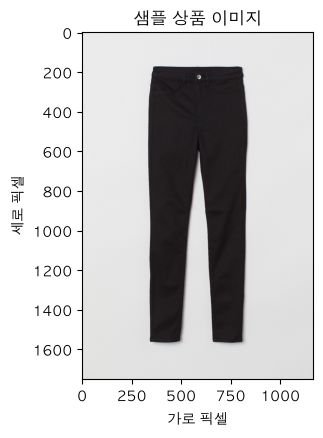

In [25]:
from matplotlib.image import imread

sample_path = analyzer.data_dir / analyzer.articles["image_path"].dropna().iloc[0]
image = imread(sample_path)  # 이미지 파일 -> NumPy 배열
print("파일:", sample_path.name)
print("shape (세로, 가로, 채널):", image.shape)
print("dtype:", image.dtype, "| 값 범위:", image.min(), "~", image.max())
print(f"이미지 1장 크기: {image.nbytes:,}바이트 -> 1,494장을 쌓으면 약 {image.nbytes * 1494 / 1e9:.1f}GB")
print(f"전체 평균: {image.mean():.2f} | 좌상단 50x50 영역 평균: {image[:50, :50].mean():.2f}")

plt.figure(figsize=(3, 4.5))
plt.imshow(image)
plt.title("샘플 상품 이미지")
plt.xlabel("가로 픽셀")
plt.ylabel("세로 픽셀")
plt.show()

**반복문과 NumPy 배열 연산 비교.** 같은 이미지의 평균과 표준편차를 (1) 값을 하나씩 도는 파이썬 반복문과 (2) NumPy 배열 연산으로 구해 값과 시간을 비교한다. 시간은 실행할 때마다 조금씩 달라진다.

In [26]:
import time

# (1) 파이썬 반복문: 값을 하나씩 더하고, 평균과의 차이를 하나씩 제곱해서 더한다.
pixels = image.ravel().tolist()
start = time.perf_counter()
total = 0
for value in pixels:
    total += value
loop_mean = total / len(pixels)
squared = 0.0
for value in pixels:
    squared += (value - loop_mean) ** 2
loop_std = (squared / len(pixels)) ** 0.5
loop_seconds = time.perf_counter() - start

# (2) NumPy 배열 연산: 배열 전체에 한 번에 적용한다.
start = time.perf_counter()
numpy_mean, numpy_std = image.mean(), image.std()
numpy_seconds = time.perf_counter() - start

print(f"값의 개수: {len(pixels):,}")
print(f"반복문: 평균 {loop_mean:.6f}, 표준편차 {loop_std:.6f} ({loop_seconds:.3f}초)")
print(f"NumPy : 평균 {numpy_mean:.6f}, 표준편차 {numpy_std:.6f} ({numpy_seconds:.4f}초)")
print("두 방법의 값이 같은가:", abs(loop_mean - numpy_mean) < 1e-6 and abs(loop_std - numpy_std) < 1e-6)
print(f"반복문이 NumPy보다 약 {loop_seconds / numpy_seconds:.0f}배 오래 걸림")

값의 개수: 6,121,500
반복문: 평균 172.688792, 표준편차 88.992240 (0.419초)
NumPy : 평균 172.688792, 표준편차 88.992240 (0.0078초)
두 방법의 값이 같은가: True
반복문이 NumPy보다 약 54배 오래 걸림


In [27]:
analyzer.add_image_features()
analyzer.articles[["article_id", "image_path", "img_mean", "img_std"]].head()

,article_id,image_path,img_mean,img_std
0,0706016001,images/070/0706016001.jpg,172.688792,88.992240
1,0720125001,images/072/0720125001.jpg,173.214989,85.564607
2,0706016002,images/070/0706016002.jpg,196.585072,57.726606
3,0372860001,images/037/0372860001.jpg,195.916482,76.869613
4,0759871002,images/075/0759871002.jpg,153.846229,99.466212


In [28]:
articles = analyzer.articles

# 위에서 따로 읽어 계산한 이미지 1장의 값과 새 컬럼 값을 비교한다.
first = articles[articles["image_path"].notna()].iloc[0]
print(f"직접 계산: 평균 {image.mean():.6f}, 표준편차 {image.std():.6f}")
print(f"컬럼 값  : 평균 {first['img_mean']:.6f}, 표준편차 {first['img_std']:.6f}")
print("일치:", first["img_mean"] == image.mean() and first["img_std"] == image.std())

# 이미지 경로가 없는 상품은 결측이다.
no_image = articles[articles["image_path"].isna()]
print(f"이미지 경로가 없는 상품 {len(no_image)}개 / img_mean 결측 {articles['img_mean'].isna().sum()}개, img_std 결측 {articles['img_std'].isna().sum()}개")
no_image[["article_id", "colour_group_name", "img_mean", "img_std"]]

직접 계산: 평균 172.688792, 표준편차 88.992240
컬럼 값  : 평균 172.688792, 표준편차 88.992240
일치: True
이미지 경로가 없는 상품 6개 / img_mean 결측 6개, img_std 결측 6개


,article_id,colour_group_name,img_mean,img_std
5,0610776002,Black,NaN,NaN
12,0610776001,White,NaN,NaN
262,0408875001,Black,NaN,NaN
401,0179208001,Black,NaN,NaN
694,0212629004,Black,NaN,NaN
1429,0788632002,Dark Beige,NaN,NaN


In [29]:
# 다운샘플링(step=4)이 값을 얼마나 바꾸는지 비교한다. 이미지를 다시 읽으므로 몇 초 걸린다.
fast = DataAnalyzer().load_data().add_image_features(step=4)
diff_mean = (fast.articles["img_mean"] - articles["img_mean"]).abs()
diff_std = (fast.articles["img_std"] - articles["img_std"]).abs()
print(f"step=4와 step=1의 최대 차이: 평균 {diff_mean.max():.3f}, 표준편차 {diff_std.max():.3f} (값의 범위는 0~255)")

step=4와 step=1의 최대 차이: 평균 0.384, 표준편차 0.499 (값의 범위는 0~255)


In [30]:
display(articles[["img_mean", "img_std"]].describe().round(2))
print(f"행 x 열: {articles.shape[0]:,} x {articles.shape[1]} (추가 전 31열)")

,img_mean,img_std
count,1494.00,1494.00
mean,189.16,62.75
std,29.43,31.13
min,30.13,2.64
25%,168.60,38.44
50%,191.03,70.81
75%,212.91,89.80
max,237.17,117.56


행 x 열: 1,500 x 33 (추가 전 31열)


**해석 — 이미지 피처**

- **수치 근거:** 이미지 1,494장의 평균 밝기 `img_mean`은 30.13~237.17(중앙값 191.03), 표준편차 `img_std`는 2.64~117.56(중앙값 70.81)이다. 샘플 이미지는 전체 평균이 172.69인데 좌상단 50x50 영역(배경 부분)의 평균은 235.22로 더 밝다.
- **시사점:** `img_mean`은 상품 자체의 색이 아니라 상품과 배경을 합친 밝기다. 이 샘플에서는 밝은 배경이 이미지의 큰 부분을 차지하므로, 어두운 옷도 평균이 높게 나올 수 있다. 이 피처를 해석할 때 "상품이 밝다"가 아니라 "사진 전체가 밝다"로 읽어야 한다. (샘플 1장으로 확인한 것이며 모든 이미지가 같다고 단정하지 않는다.)
- **수치 근거:** 다운샘플링 `step=4`로 계산한 값은 `step=1`과 최대 0.384(평균), 0.499(표준편차)만 달랐다.
- **시사점:** 값의 범위가 0~255인 데 비해 차이가 작아서, 이미지가 훨씬 많거나 커졌을 때 `step`을 키워 계산 시간을 줄여도 피처의 의미는 거의 유지된다.
- **수치 근거:** 이미지 경로가 없는 상품 6개는 두 피처가 결측이다.
- **시사점:** 이 결측은 5단계에서 그룹별 통계로 대치해야 이후 분석에 쓸 수 있다.